# Task 2: California Housing Price Prediction (OLS vs Ridge vs Lasso)
Goal: predict median house value, engineer features, handle multicollinearity, tune Ridge/Lasso with `GridSearchCV`, and compare models on RMSE, MAE and R².

## 1. Load the dataset

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style='whitegrid')
housing = fetch_california_housing(as_frame=True)   # downloaded automatically by scikit-learn
df = housing.frame.copy()
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Target `MedHouseVal` is in units of $100,000.

## 2. Missing values and correlation heatmap

In [2]:
print(df.isna().sum())
print('Total missing:', df.isna().sum().sum())

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64
Total missing: 0


The original dataset has no nulls, so the imputer below will not change anything. It is still included in the pipeline (median strategy), so the code would handle missing data in a new dataset.

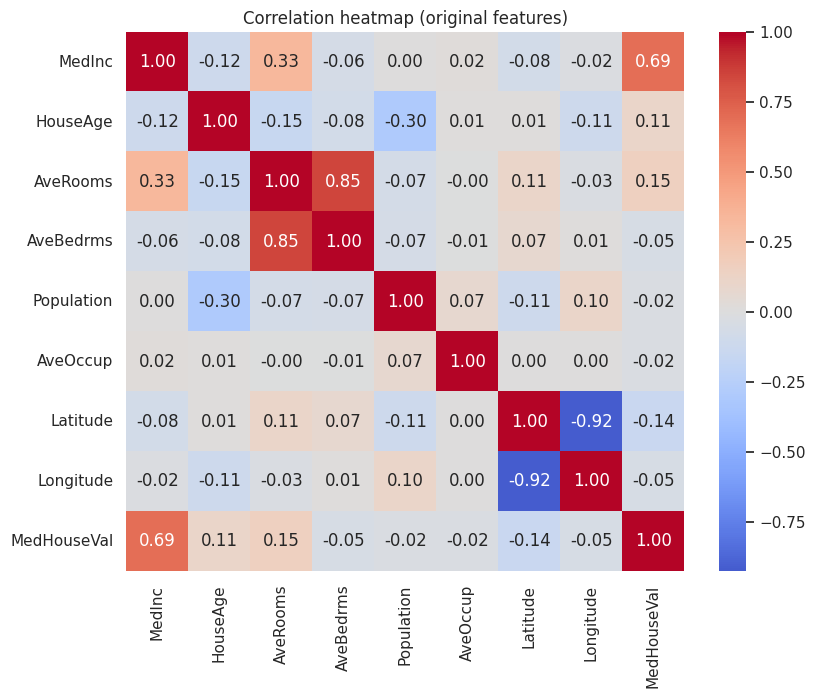

In [3]:
plt.figure(figsize=(9,7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation heatmap (original features)')
plt.show()

## 3. Feature engineering
- **Interaction features:** `MedInc x HouseAge`, `MedInc x AveRooms`, `Latitude x Longitude`
- **Ratio features:** `BedrmsPerRoom`, `RoomsPerPerson`
- **Categorical feature:** `IncomeLevel` (Low/Medium/High/Very High bins of `MedInc`), then one-hot encoded. The dataset has no categorical columns, so this demonstrates the encoding step.

In [4]:
fe = df.copy()
fe['MedInc_x_HouseAge'] = fe['MedInc'] * fe['HouseAge']
fe['MedInc_x_AveRooms'] = fe['MedInc'] * fe['AveRooms']
fe['Lat_x_Long'] = fe['Latitude'] * fe['Longitude']
fe['BedrmsPerRoom'] = fe['AveBedrms'] / fe['AveRooms']
fe['RoomsPerPerson'] = fe['AveRooms'] / fe['AveOccup']
fe['IncomeLevel'] = pd.qcut(fe['MedInc'], 4, labels=['Low','Medium','High','VeryHigh'])
fe = pd.get_dummies(fe, columns=['IncomeLevel'], drop_first=True, dtype=int)
fe.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,MedInc_x_HouseAge,MedInc_x_AveRooms,Lat_x_Long,BedrmsPerRoom,RoomsPerPerson,IncomeLevel_Medium,IncomeLevel_High,IncomeLevel_VeryHigh
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,341.3332,58.144254,-4630.0724,0.146591,2.732919,0,0,1
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,174.3294,51.785271,-4627.2492,0.155797,2.956685,0,0,1
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,377.3848,60.150315,-4626.7840,0.129516,2.957661,0,0,1
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,293.4412,32.827897,-4627.1625,0.184458,2.283154,0,0,1
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,200.0024,24.161264,-4627.1625,0.172096,2.879646,0,1,0


## 4. Multicollinearity check (VIF)
VIF above 10 signals strong multicollinearity. VIF is computed from the inverse of the correlation matrix.

In [5]:
def vif_table(frame):
    corr = np.corrcoef(frame.values, rowvar=False)
    vif = np.diag(np.linalg.inv(corr))
    return pd.Series(vif, index=frame.columns).sort_values(ascending=False).round(2)

X_all = fe.drop(columns='MedHouseVal')
vif = vif_table(X_all)
print(vif.head(10))

Lat_x_Long              13344.44
Latitude                 8401.01
Longitude                 654.54
AveRooms                   32.17
MedInc                     30.29
MedInc_x_AveRooms          22.88
AveBedrms                  18.41
MedInc_x_HouseAge           9.15
IncomeLevel_VeryHigh        7.17
RoomsPerPerson              5.74
dtype: float64


Ridge and Lasso handle correlated features: Ridge shrinks correlated coefficients together, and Lasso can drive some to exactly zero. We keep all features and let the regularized models deal with them, then compare against plain OLS.

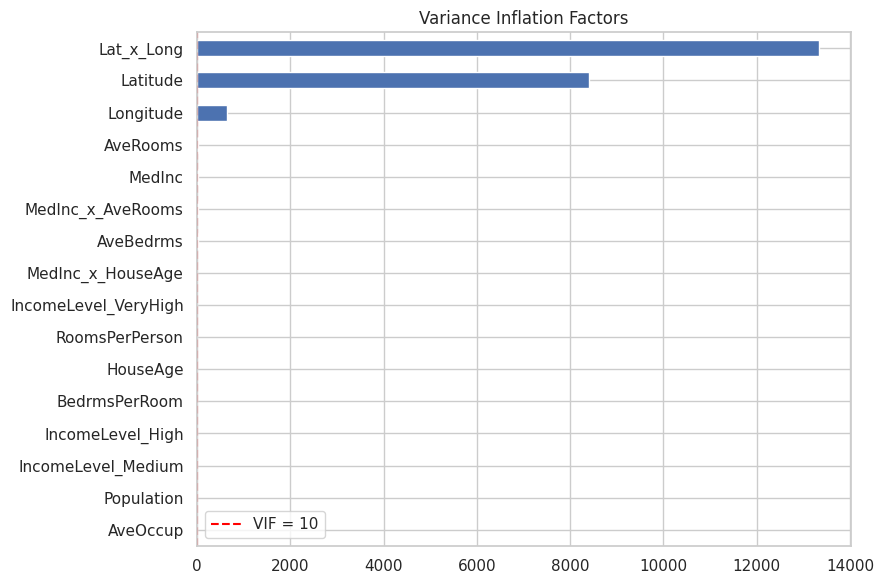

In [6]:
plt.figure(figsize=(9,6))
vif.sort_values().plot(kind='barh')
plt.axvline(10, color='red', linestyle='--', label='VIF = 10')
plt.title('Variance Inflation Factors'); plt.legend(); plt.tight_layout(); plt.show()

## 5. Train/test split, imputation and scaling
The imputer and scaler are fit inside a pipeline, so they are learned from training data only (no leakage).

In [7]:
X = fe.drop(columns='MedHouseVal')
y = fe['MedHouseVal']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

def make_pipe(model):
    return Pipeline([('imputer', SimpleImputer(strategy='median')),
                     ('scaler', StandardScaler()),
                     ('model', model)])
print(X_train.shape, X_test.shape)

(16512, 16) (4128, 16)


## 6. Fit OLS, Ridge and Lasso (GridSearchCV over alpha)

In [8]:
ols = make_pipe(LinearRegression()).fit(X_train, y_train)

ridge_grid = GridSearchCV(make_pipe(Ridge()),
    {'model__alpha': np.logspace(-3, 3, 13)}, cv=5,
    scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, y_train)

lasso_grid = GridSearchCV(make_pipe(Lasso(max_iter=20000)),
    {'model__alpha': np.logspace(-4, 0, 13)}, cv=5,
    scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_train, y_train)

print('Best Ridge alpha:', ridge_grid.best_params_['model__alpha'])
print('Best Lasso alpha:', lasso_grid.best_params_['model__alpha'])

Best Ridge alpha: 0.31622776601683794
Best Lasso alpha: 0.0001


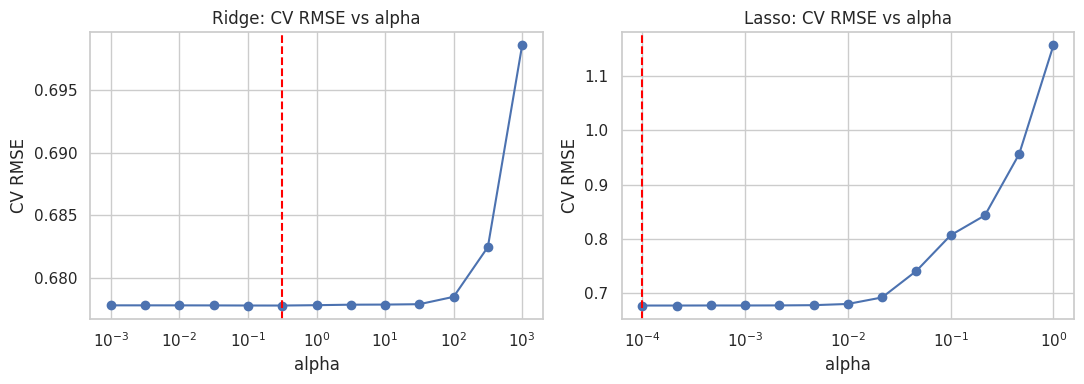

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for ax, g, name in zip(axes, [ridge_grid, lasso_grid], ['Ridge', 'Lasso']):
    alphas = g.cv_results_['param_model__alpha'].astype(float)
    ax.semilogx(alphas, -g.cv_results_['mean_test_score'], marker='o')
    ax.axvline(g.best_params_['model__alpha'], color='red', linestyle='--')
    ax.set_title(f'{name}: CV RMSE vs alpha'); ax.set_xlabel('alpha'); ax.set_ylabel('CV RMSE')
plt.tight_layout(); plt.show()

## 7. Compare models on the test set

In [10]:
models = {'OLS': ols,
          'Ridge (L2)': ridge_grid.best_estimator_,
          'Lasso (L1)': lasso_grid.best_estimator_}
preds, rows = {}, []
for name, m in models.items():
    p = m.predict(X_test); preds[name] = p
    rows.append({'Model': name,
                 'RMSE': np.sqrt(mean_squared_error(y_test, p)),
                 'MAE': mean_absolute_error(y_test, p),
                 'R2': r2_score(y_test, p)})
results = pd.DataFrame(rows).set_index('Model').round(4)
display(results)

,RMSE,MAE,R2
Model,,,
OLS,0.6739,0.4848,0.6535
Ridge (L2),0.6739,0.4848,0.6534
Lasso (L1),0.6740,0.4849,0.6533


,OLS,Ridge (L2),Lasso (L1)
MedInc,0.749,0.749,0.747
HouseAge,0.067,0.067,0.067
AveRooms,-0.025,-0.024,-0.024
AveBedrms,-0.275,-0.274,-0.273
Population,0.032,0.032,0.032
AveOccup,-0.021,-0.021,-0.021
Latitude,1.014,0.525,-0.000
Longitude,-1.328,-1.192,-1.046
MedInc_x_HouseAge,0.099,0.099,0.099
MedInc_x_AveRooms,-0.150,-0.149,-0.147


Features zeroed out by Lasso: ['Latitude']


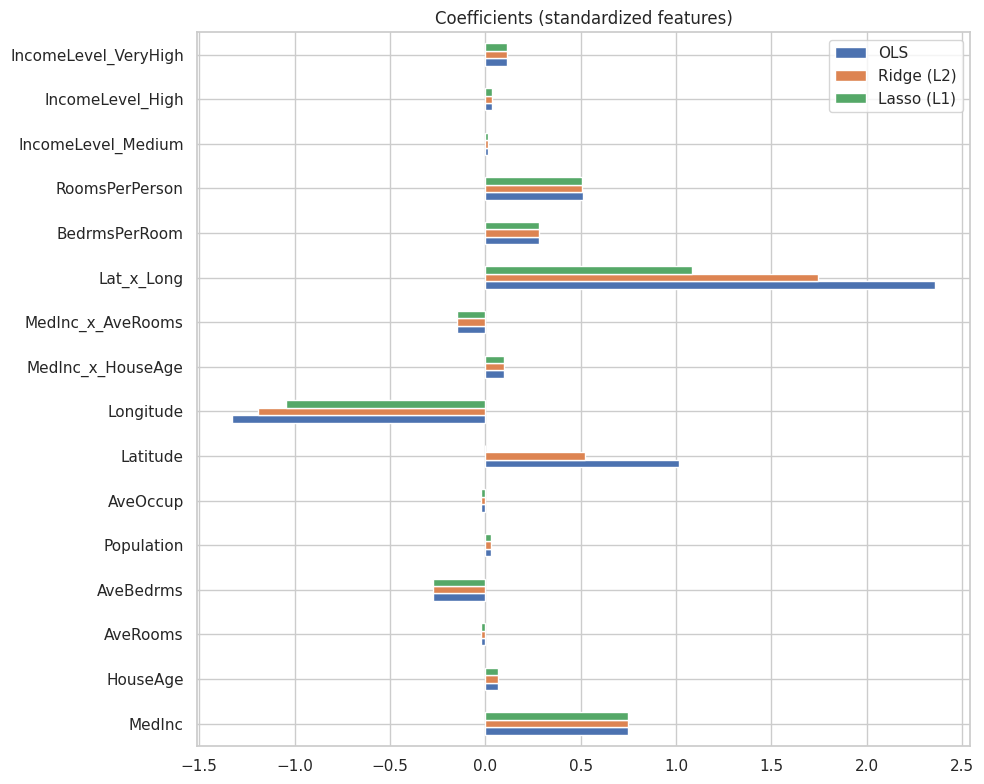

In [11]:
coefs = pd.DataFrame({name: m.named_steps['model'].coef_ for name, m in models.items()}, index=X.columns)
display(coefs.round(3))
print('Features zeroed out by Lasso:', list(coefs.index[coefs['Lasso (L1)'] == 0]))
coefs.plot(kind='barh', figsize=(10,8)); plt.title('Coefficients (standardized features)')
plt.tight_layout(); plt.show()

## 8. Predicted vs actual

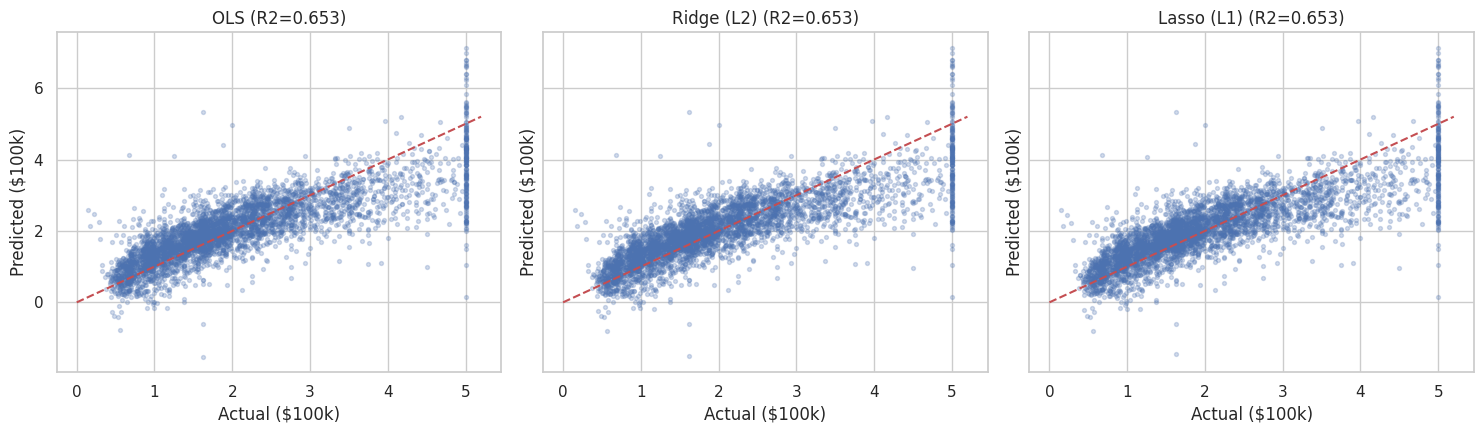

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15,4.5), sharex=True, sharey=True)
lims = [0, 5.2]
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test, p, alpha=0.25, s=8)
    ax.plot(lims, lims, 'r--')
    ax.set_title(f"{name} (R2={results.loc[name,'R2']:.3f})")
    ax.set_xlabel('Actual ($100k)'); ax.set_ylabel('Predicted ($100k)')
plt.tight_layout(); plt.show()

## 9. Residual analysis

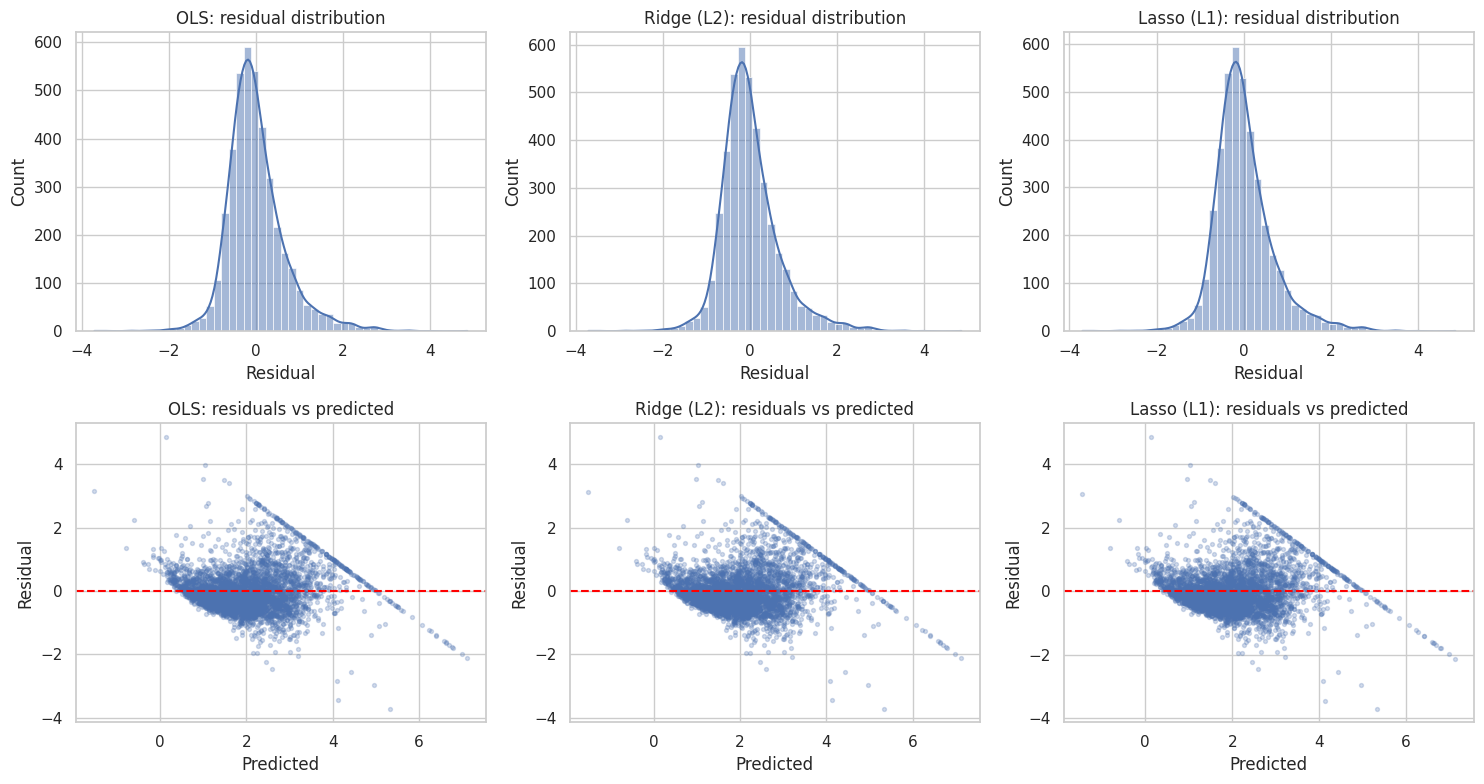

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15,8))
for i, (name, p) in enumerate(preds.items()):
    res = y_test - p
    sns.histplot(res, kde=True, ax=axes[0, i], bins=50)
    axes[0, i].set_title(f'{name}: residual distribution'); axes[0, i].set_xlabel('Residual')
    axes[1, i].scatter(p, res, alpha=0.25, s=8)
    axes[1, i].axhline(0, color='red', linestyle='--')
    axes[1, i].set_title(f'{name}: residuals vs predicted')
    axes[1, i].set_xlabel('Predicted'); axes[1, i].set_ylabel('Residual')
plt.tight_layout(); plt.show()